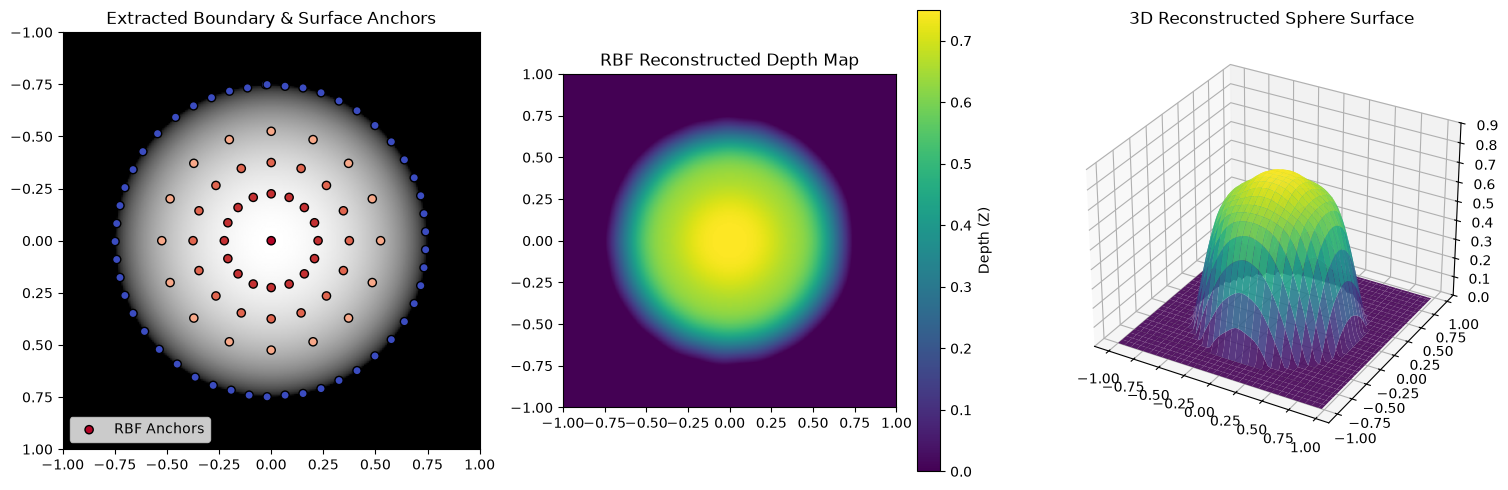

Reconstruction RMSE on Sphere Region: 0.0753


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import Rbf
from mpl_toolkits.mplot3d import Axes3D

# -------------------------------------------------------------
# Step 1: Generate or Load Synthetic Shaded Sphere Image
# -------------------------------------------------------------
img_size = 256
x = np.linspace(-1, 1, img_size)
y = np.linspace(-1, 1, img_size)
X, Y = np.meshgrid(x, y)
R_true = 0.75
mask_true = (X**2 + Y**2) <= R_true**2

# Ground truth visible hemisphere
Z_true = np.zeros_like(X)
Z_true[mask_true] = np.sqrt(np.maximum(0.0, R_true**2 - X[mask_true]**2 - Y[mask_true]**2))

# Lambertian shading under frontal-top light
L = np.array([0.0, 0.0, 1.0])
N_x = np.where(mask_true, X / R_true, 0.0)
N_y = np.where(mask_true, Y / R_true, 0.0)
N_z = np.where(mask_true, Z_true / R_true, 0.0)
I_shaded = np.clip(N_z, 0, 1)

# Convert to 8-bit image for OpenCV
img_u8 = (I_shaded * 255).astype(np.uint8)

# -------------------------------------------------------------
# Step 2: Boundary & Apex Extraction via OpenCV
# -------------------------------------------------------------
# Threshold to find circular silhouette mask
_, thresh = cv2.threshold(img_u8, 5, 255, cv2.THRESH_BINARY)
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
c = max(contours, key=cv2.contourArea)

# Fit enclosing circle: center (cx, cy) and radius r_px
(cx, cy), r_px = cv2.minEnclosingCircle(c)
cx, cy, r_px = float(cx), float(cy), float(r_px)

# Convert pixel coordinates to normalized grid [-1, 1]
def to_norm(px, py):
    nx = (px / (img_size - 1)) * 2.0 - 1.0
    ny = (py / (img_size - 1)) * 2.0 - 1.0
    return nx, ny

cx_n, cy_n = to_norm(cx, cy)
r_n = (r_px / (img_size - 1)) * 2.0

# -------------------------------------------------------------
# Step 3: Construct RBF Control Points
# -------------------------------------------------------------
pts_x, pts_y, pts_z = [], [], []

# Constraint 1: Apex (Peak Depth)
pts_x.append(cx_n)
pts_y.append(cy_n)
pts_z.append(r_n)  # z_apex = R

# Constraint 2: Sample points along silhouette boundary (z = 0)
num_rim_samples = 48
boundary_pts = c[::max(1, len(c) // num_rim_samples)]
for pt in boundary_pts:
    bx, by = pt[0]
    bx_n, by_n = to_norm(bx, by)
    pts_x.append(bx_n)
    pts_y.append(by_n)
    pts_z.append(0.0)

# Constraint 3: Intermediate radial samples (using diffuse shading cue: z = R * cos(theta))
# Since intensity I ~ cos(theta) for frontal light, z_inter ~ R * (I / I_max)
radii_fractions = [0.3, 0.5, 0.7]
angles = np.linspace(0, 2 * np.pi, 16, endpoint=False)
for rf in radii_fractions:
    for ang in angles:
        sx = cx_n + rf * r_n * np.cos(ang)
        sy = cy_n + rf * r_n * np.sin(ang)
        # Depth for a sphere: z = sqrt(R^2 - r^2)
        sz = np.sqrt(max(0.0, r_n**2 - (rf * r_n)**2))
        pts_x.append(sx)
        pts_y.append(sy)
        pts_z.append(sz)

pts_x = np.array(pts_x)
pts_y = np.array(pts_y)
pts_z = np.array(pts_z)

# -------------------------------------------------------------
# Step 4: Fit RBF Model and Reconstruct Dense Depth Map
# -------------------------------------------------------------
# Available kernels: 'multiquadric', 'gaussian', 'inverse', 'thin_plate'
rbf_model = Rbf(pts_x, pts_y, pts_z, function='multiquadric', smooth=1e-3)

# Evaluate on full 2D grid
Z_reconstructed = rbf_model(X, Y)

# Mask out background outside estimated radius
mask_est = ((X - cx_n)**2 + (Y - cy_n)**2) <= r_n**2
Z_reconstructed[~mask_est] = 0.0
Z_reconstructed = np.maximum(0.0, Z_reconstructed)

# -------------------------------------------------------------
# Step 5: Visualization
# -------------------------------------------------------------
fig = plt.figure(figsize=(15, 5))

# Panel 1: Original Image with Sampled Control Points
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(img_u8, cmap='gray', extent=[-1, 1, 1, -1])
ax1.scatter(pts_x, pts_y, c=pts_z, cmap='coolwarm', edgecolors='black', s=35, label='RBF Anchors')
ax1.set_title('Extracted Boundary & Surface Anchors')
ax1.legend(loc='lower left')

# Panel 2: Reconstructed 2D Depth Map
ax2 = fig.add_subplot(1, 3, 2)
im = ax2.imshow(Z_reconstructed, cmap='viridis', extent=[-1, 1, -1, 1])
fig.colorbar(im, ax=ax2, label='Depth (Z)')
ax2.set_title('RBF Reconstructed Depth Map')

# Panel 3: 3D Surface Reconstruction
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
skip = 4
surf = ax3.plot_surface(X[::skip, ::skip], Y[::skip, ::skip], Z_reconstructed[::skip, ::skip],
                        cmap='viridis', edgecolor='none', alpha=0.9)
ax3.set_title('3D Reconstructed Sphere Surface')
ax3.set_zlim(0, R_true * 1.2)
plt.tight_layout()
plt.show()

# Quantitative Error Metric
rmse = np.sqrt(np.mean((Z_true[mask_true] - Z_reconstructed[mask_true])**2))
print(f"Reconstruction RMSE on Sphere Region: {rmse:.4f}")

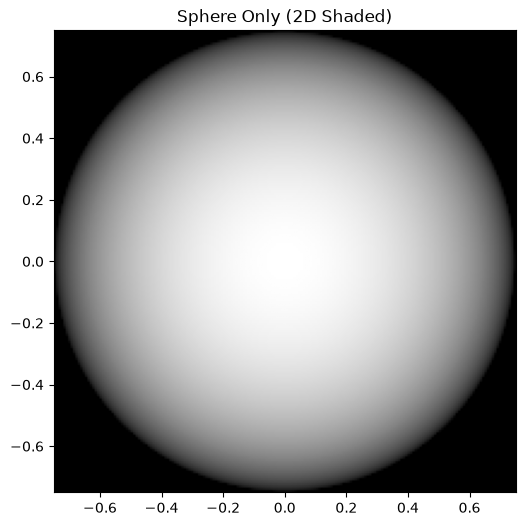

In [3]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(6, 6))

# Display the shaded sphere image
ax.imshow(img_u8, cmap='gray', extent=[-1, 1, -1, 1])

# Crop tightly to the sphere's actual radius
ax.set_xlim(-R_true, R_true)
ax.set_ylim(-R_true, R_true)

ax.set_title('Sphere Only (2D Shaded)')
ax.set_aspect('equal')
plt.show()


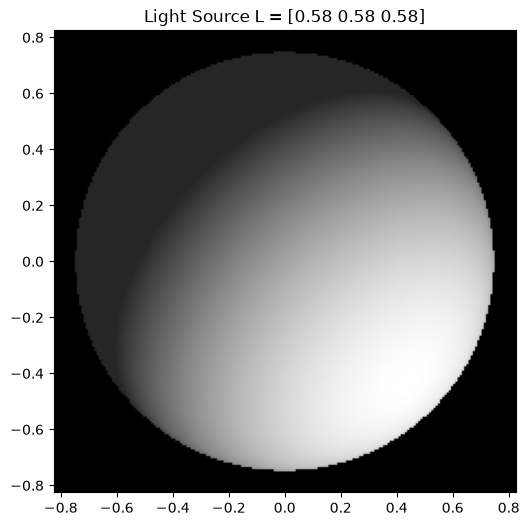

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Grid and sphere geometry
img_size = 256
x = np.linspace(-1, 1, img_size)
y = np.linspace(-1, 1, img_size)
X, Y = np.meshgrid(x, y)
R_true = 0.75
mask_true = (X**2 + Y**2) <= R_true**2

Z_true = np.zeros_like(X)
Z_true[mask_true] = np.sqrt(np.maximum(0.0, R_true**2 - X[mask_true]**2 - Y[mask_true]**2))

# 2. Compute Unit Normal Vectors (N) for every point on the sphere
N_x = np.where(mask_true, X / R_true, 0.0)
N_y = np.where(mask_true, Y / R_true, 0.0)
N_z = np.where(mask_true, Z_true / R_true, 0.0)

# -------------------------------------------------------------
# 3. Define the Light Source Vector (L = [Lx, Ly, Lz])
# -------------------------------------------------------------
# Examples:
# [ 0.0,  0.0, 1.0] -> Frontal (centered)
# [ 1.0,  1.0, 1.0] -> Top-Right & Front
# [-1.0,  1.0, 0.5] -> Top-Left
# [-1.0, -1.0, 1.0] -> Bottom-Left

L_raw = np.array([1.0, 1.0, 1.0])          # Light coming from top-right
L = L_raw / np.linalg.norm(L_raw)            # MUST be a unit vector!

# 4. Lambertian Shading: Dot Product N . L
N_dot_L = N_x * L[0] + N_y * L[1] + N_z * L[2]

# Diffuse component clamped at 0 (self-shadowing)
k_d = 0.85                                  # Diffuse reflection coefficient
k_a = 0.15                                  # Ambient light (prevents pitch-black shadows)

I_shaded = np.where(mask_true, k_a + k_d * np.maximum(0.0, N_dot_L), 0.0)
I_shaded = np.clip(I_shaded, 0.0, 1.0)

# Convert to 8-bit image
img_u8 = (I_shaded * 255).astype(np.uint8)

# 5. Plot the Shaded 2D Sphere
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img_u8, cmap='gray', extent=[-1, 1, -1, 1])
ax.set_title(f'Light Source L = {np.round(L, 2)}')
ax.set_xlim(-R_true * 1.1, R_true * 1.1)
ax.set_ylim(-R_true * 1.1, R_true * 1.1)
plt.show()


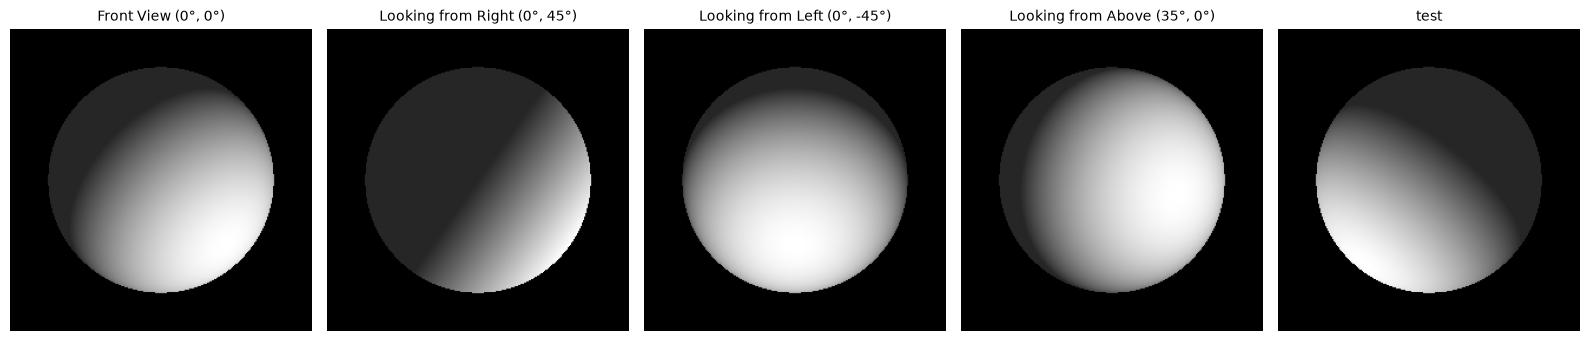

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def get_rotation_matrix(elevation_deg, azimuth_deg):
    """Rotation matrix for camera view angles (in degrees)."""
    el = np.radians(elevation_deg)
    az = np.radians(azimuth_deg)
    
    # Rotation around X-axis (elevation / pitch)
    Rx = np.array([
        [1,          0,           0],
        [0, np.cos(el), -np.sin(el)],
        [0, np.sin(el),  np.cos(el)]
    ])
    
    # Rotation around Y-axis (azimuth / yaw)
    Ry = np.array([
        [ np.cos(az), 0, np.sin(az)],
        [          0, 1,          0],
        [-np.sin(az), 0, np.cos(az)]
    ])
    
    return Rx @ Ry

# 1. 2D grid setup
img_size = 256
x = np.linspace(-1, 1, img_size)
y = np.linspace(-1, 1, img_size)
X, Y = np.meshgrid(x, y)
R_true = 0.75
mask_true = (X**2 + Y**2) <= R_true**2

Z_true = np.zeros_like(X)
Z_true[mask_true] = np.sqrt(np.maximum(0.0, R_true**2 - X[mask_true]**2 - Y[mask_true]**2))

# Surface unit normals in the camera's image plane
N_x = np.where(mask_true, X / R_true, 0.0)
N_y = np.where(mask_true, Y / R_true, 0.0)
N_z = np.where(mask_true, Z_true / R_true, 0.0)

# 2. Fixed World Light Source (e.g., coming from the top-right in the room)
L_world = np.array([1.0, 1.0, 1.0])
L_world = L_world / np.linalg.norm(L_world)

# 3. Simulate different viewing angles (Elevation, Azimuth)
views = [
    ("Front View (0°, 0°)", 0, 0),
    ("Looking from Right (0°, 45°)", 0, 45),
    ("Looking from Left (0°, -45°)", 0, -45),
    ("Looking from Above (35°, 0°)", 35, 0),
    ("test", 70, 180)
]

fig, axes = plt.subplots(1, len(views), figsize=(16, 4))

for ax, (title, elev, azim) in zip(axes, views):
    # Rotate the light vector according to the camera's viewpoint
    R_view = get_rotation_matrix(elev, azim)
    L_cam = R_view @ L_world
    
    # Compute Lambertian shading in camera view
    N_dot_L = N_x * L_cam[0] + N_y * L_cam[1] + N_z * L_cam[2]
    I_shaded = np.where(mask_true, 0.15 + 0.85 * np.maximum(0.0, N_dot_L), 0.0)
    
    ax.imshow(I_shaded, cmap='gray', extent=[-1, 1, -1, 1])
    ax.set_title(title, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()


In [19]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Sphere geometry
img_size = 256
x = np.linspace(-1, 1, img_size)
y = np.linspace(-1, 1, img_size)
X, Y = np.meshgrid(x, y)
R_true = 0.75
mask_true = (X**2 + Y**2) <= R_true**2

Z_true = np.zeros_like(X)
Z_true[mask_true] = np.sqrt(np.maximum(0.0, R_true**2 - X[mask_true]**2 - Y[mask_true]**2))

# Surface normal vectors
N_x = np.where(mask_true, X / R_true, 0.0)
N_y = np.where(mask_true, Y / R_true, 0.0)
N_z = np.where(mask_true, Z_true / R_true, 0.0)

# -------------------------------------------------------------
# 2. Point Light Source Position: P_light = [X_L, Y_L, Z_L]
# -------------------------------------------------------------
# Here, Z_L directly controls the distance of the light in front of the sphere!
P_light = np.array([0.0, 0.0, 1.5])    # 3D position of the bulb

# Vector from every point on the sphere (X, Y, Z) to the light source
dx = P_light[0] - X
dy = P_light[1] - Y
dz = P_light[2] - Z_true

# -------------------------------------------------------------
# THIS IS THE DISTANCE VARIABLE: d
# -------------------------------------------------------------
d = np.sqrt(dx**2 + dy**2 + dz**2)     # Euclidean distance to each point

# Unit light direction at each pixel (rays are NOT parallel anymore!)
L_x = dx / d
L_y = dy / d
L_z = dz / d

# Shading: N . L
N_dot_L = N_x * L_x + N_y * L_y + N_z * L_z

# Inverse-Square Law Attenuation: 1 / d^2
attenuation = 1.0 / (d**2)

# Final intensity
I_shaded = np.where(mask_true, np.maximum(0.0, N_dot_L) * attenuation, 0.0)

# Normalize for display
I_shaded = I_shaded / np.max(I_shaded)


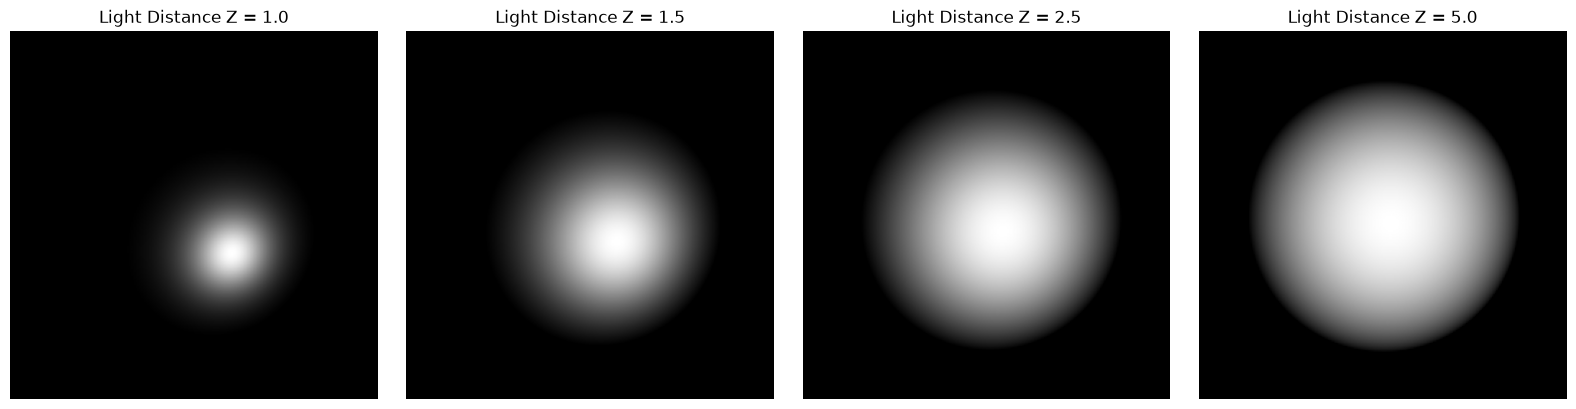

In [20]:
# Compare 4 different light distances along Z: z = 1.0 (very close) to z = 5.0 (far)
distances = [1.0, 1.5, 2.5, 5.0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, z_dist in zip(axes, distances):
    P = np.array([0.3, 0.3, z_dist])
    
    # Distance calculation
    dx = P[0] - X
    dy = P[1] - Y
    dz = P[2] - Z_true
    d = np.sqrt(dx**2 + dy**2 + dz**2)
    
    # Direction and attenuation
    dot = N_x * (dx / d) + N_y * (dy / d) + N_z * (dz / d)
    attenuation = 1.0 / (d**2)
    
    I = np.where(mask_true, np.maximum(0.0, dot) * attenuation, 0.0)
    I = I / np.max(I)  # Normalize
    
    ax.imshow(I, cmap='gray', extent=[-1, 1, -1, 1])
    ax.set_title(f"Light Distance Z = {z_dist}")
    ax.axis('off')

plt.tight_layout()
plt.show()


In [25]:
%matplotlib tk

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

# ============================================================
# 1. REUSE PRECOMPUTED SPHERE & ILLUMINATION MODEL
# ============================================================
ambient = 0.08
light_power = 2

def calculate_illumination(azimuth, elevation, distance):
    az, el = np.radians(azimuth), np.radians(elevation)
    
    # 3D position of the point light source
    Lx = distance * np.cos(el) * np.cos(az)
    Ly = distance * np.cos(el) * np.sin(az)
    Lz = distance * np.sin(el)
    
    # Vector and distance from every sphere point to the light (reusing X, Y, Z_true)
    dx = Lx - X
    dy = Ly - Y
    dz = Lz - Z_true
    d = np.maximum(np.sqrt(dx**2 + dy**2 + dz**2), 1e-6)
    
    # Lambertian shading (reusing N_x, N_y, N_z)
    diffuse = np.maximum(N_x * (dx / d) + N_y * (dy / d) + N_z * (dz / d), 0.0)
    
    # Shading with inverse-square law attenuation
    intensity = np.where(mask_true, ambient + light_power * diffuse / (d**2), 0.18)
    return np.clip(intensity, 0, 1), np.array([Lx, Ly, Lz])

# Baseline image for difference comparison
init_az, init_el, init_dist = 180, 25, 2.0
base_img, base_pos = calculate_illumination(init_az, init_el, init_dist)
base_u8 = (base_img * 255).astype(np.uint8)

# ============================================================
# 2. 3D SURFACE MESH (Downsampling X, Y, Z_true from Cell 0)
# ============================================================
skip = 4
X3, Y3, Z3 = X[::skip, ::skip], Y[::skip, ::skip], Z_true[::skip, ::skip]
M3 = mask_true[::skip, ::skip]

def get_facecolors(img_2d):
    sub = img_2d[::skip, ::skip]
    colors = plt.cm.gray(sub)
    colors[~M3, 3] = 0.0  # Make points outside the sphere transparent
    return colors

# ============================================================
# 3. SETUP 6-PANEL FIGURE
# ============================================================
fig = plt.figure(figsize=(15, 9))
fig.subplots_adjust(bottom=0.28, wspace=0.35, hspace=0.35)

ax_img = fig.add_subplot(231)
ax_3d = fig.add_subplot(232, projection="3d")
ax_diff = fig.add_subplot(233)
ax_prof = fig.add_subplot(234)
ax_hist = fig.add_subplot(235)
ax_info = fig.add_subplot(236)

# 1. 2D image
im = ax_img.imshow(base_u8, cmap="gray", vmin=0, vmax=255, extent=[-1, 1, -1, 1])
ax_img.set_title("Illuminated Sphere (2D)")

# 2. 3D surface & light marker
surf = ax_3d.plot_surface(X3, Y3, Z3, facecolors=get_facecolors(base_img), linewidth=0, shade=False)
light_marker = ax_3d.scatter([base_pos[0]], [base_pos[1]], [base_pos[2]], color="red", s=80, label="Light Source")
ax_3d.set_title("3D Surface Illumination")
ax_3d.set_xlim(-3, 3); ax_3d.set_ylim(-3, 3); ax_3d.set_zlim(-0.1, 3)
ax_3d.legend(loc="upper left")

# 3. Difference map
diff_im = ax_diff.imshow(np.zeros_like(base_u8), cmap="magma", vmin=0, vmax=255, extent=[-1, 1, -1, 1])
ax_diff.set_title("Difference from Initial")

# 4. Profile
row = img_size // 2
line_prof, = ax_prof.plot(base_u8[row, :], label="Profile")
ax_prof.set_title(f"Horizontal Profile (Row {row})")
ax_prof.set_ylim(0, 260)
ax_prof.grid(True, alpha=0.3)

# 5. Histogram
ax_hist.hist(base_u8.ravel(), bins=32, range=(0, 255), alpha=0.7)
ax_hist.set_title("Intensity Histogram")

# 6. Info text
ax_info.axis("off")
info_text = ax_info.text(0.05, 0.85, "", fontsize=11, va="top")

# ============================================================
# 4. SLIDERS & LIVE UPDATE
# ============================================================
ax_az = fig.add_axes([0.18, 0.18, 0.65, 0.025])
ax_el = fig.add_axes([0.18, 0.13, 0.65, 0.025])
ax_dist = fig.add_axes([0.18, 0.08, 0.65, 0.025])

s_az = Slider(ax_az, "Azimuth (°)", 0, 360, valinit=init_az)
s_el = Slider(ax_el, "Elevation (°)", 5, 90, valinit=init_el)
s_dist = Slider(ax_dist, "Distance", 1.0, 4.0, valinit=init_dist)

def update(val):
    global surf, light_marker
    az, el, dist = s_az.val, s_el.val, s_dist.val
    new_img, l_pos = calculate_illumination(az, el, dist)
    new_u8 = (new_img * 255).astype(np.uint8)

    # Update panels
    im.set_data(new_u8)
    
    surf.remove()
    surf = ax_3d.plot_surface(X3, Y3, Z3, facecolors=get_facecolors(new_img), linewidth=0, shade=False)
    
    light_marker.remove()
    light_marker = ax_3d.scatter([l_pos[0]], [l_pos[1]], [l_pos[2]], color="red", s=80)
    
    diff_im.set_data(np.abs(new_u8.astype(float) - base_u8.astype(float)))
    line_prof.set_ydata(new_u8[row, :])
    
    ax_hist.clear()
    ax_hist.hist(new_u8.ravel(), bins=32, range=(0, 255), alpha=0.7)
    ax_hist.set_title("Intensity Histogram")
    
    info_text.set_text(
        f"LIGHT SOURCE\n\n"
        f"Azimuth:   {az:.1f}°\n"
        f"Elevation: {el:.1f}°\n"
        f"Distance:  {dist:.2f}\n\n"
        f"Position:\n"
        f"X = {l_pos[0]:.2f}\n"
        f"Y = {l_pos[1]:.2f}\n"
        f"Z = {l_pos[2]:.2f}"
    )
    fig.canvas.draw_idle()

s_az.on_changed(update)
s_el.on_changed(update)
s_dist.on_changed(update)

update(None)
plt.show()
